# XDP sample Used: "SCF-20-025"

# Make Accout Base Jump (Lab email)

https://basejumper.bioskryb.com/#/workspace/b9dbc50e-af67-4afa-b77a-3b0364c988e1/projects/DNA

# Make Account in GLobus (my broad email)

https://app.globus.org/dashboard


# Ask for a Globus account htog email

"""
Hello BaseJumper team,

I'm a member of the Macosko lab at the Broad Institute. We would like to upload sequencing data to our lab's BaseJumper account to run the BJ-Expression pipeline.

Could you please set up both of the following for our lab's account:

1. A Globus group invitation for our BaseJumper workspace
2. sFTP upload credentials (key, username and password via Keeper)

Details:
- Lab BaseJumper account: macoskolabops@broadinstitute.org (CC'd on this email)
- Please send the Globus invitation and the Keeper sFTP credentials to me: gdallagl@broadinstitute.org

Once uploaded, could you also make sure the files are linked to our lab's workspace, or let me know if there is a step I need to do on my side?

Separately, you may want to know that the BJ-Expression GitHub README says the pipeline resources in s3://bioskryb-public-data/pipeline_resources are public, but they currently return 403 Access Denied, including the test FASTQs and the GRCh38 STAR/Salmon indexes.

Thank you,
Gabri
"""

# Download Globus on this VM

In [1]:
%%bash

cd ~/myworkdir/tools
wget https://downloads.globus.org/globus-connect-personal/linux/stable/globusconnectpersonal-latest.tgz
tar xzf globusconnectpersonal-latest.tgz
ls -d globusconnectpersonal-*/        # note the exact folder name (version number)
cd globusconnectpersonal-*/

--2026-10-21 15:19:32--  https://downloads.globus.org/globus-connect-personal/linux/stable/globusconnectpersonal-latest.tgz
Resolving downloads.globus.org (downloads.globus.org)... 3.162.174.42, 3.162.174.62, 3.162.174.47, ...
Connecting to downloads.globus.org (downloads.globus.org)|3.162.174.42|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 138877692 (132M) [application/x-tar]
Saving to: ‘globusconnectpersonal-latest.tgz’

     0K .......... .......... .......... .......... ..........  0% 4.04M 33s
    50K .......... .......... .......... .......... ..........  0% 5.18M 29s
   100K .......... .......... .......... .......... ..........  0% 11.8M 23s
   150K .......... .......... .......... .......... ..........  0% 14.9M 20s
   200K .......... .......... .......... .......... ..........  0% 13.4M 18s
   250K .......... .......... .......... .......... ..........  0% 18.4M 16s
   300K .......... .......... .......... .......... ..........  0% 15.8M 15s
   35

globusconnectpersonal-3.3.1/


In [ ]:
# Must be done in terminal

"""
cd ~/myworkdir/tools/globusconnectpersonal-3.3.1
./globusconnectpersonal -setup --no-gui --name gdallagl-gpu-vm


It prints a long web address. 
Open it in your laptop’s browser and log in with your Broad identity.
Copy the authorization code the page shows, paste it into the terminal, and press Enter.
"""

--name is required (unless --setup-key is used)


Setup did not complete successfully.
You may want to check /home/gdallagl/.globusonline/lta/register.log for more information


CalledProcessError: Command 'b'\ncd ~/myworkdir/tools\ncd globusconnectpersonal-*/\n./globusconnectpersonal -setup --no-gui\n'' returned non-zero exit status 2.

In [2]:
%%bash

cd ~/myworkdir/tools/globusconnectpersonal-3.3.1
./globusconnectpersonal -stop
nohup ./globusconnectpersonal -start > ~/globus_personal.log 2>&1 &
sleep 5
./globusconnectpersonal -status

Globus Connect Personal is currently running and connected to Globus Online
Sending stop signal... Done


Globus Online:   connected
Transfer Status: idle


# Copy RNA libs here from bucket

In [ ]:

%%bash

BUCKET_PATH="gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559aa7d36/fastqs/260826_SL-EXL_0486_A2535GJLT4/WALKUP-21131_0457512804_2026-08-28--14-56-01/fastq"

SAVE_PATH="/home/gdallagl/myworkdir/data/XDP/G_and_T/rna_libs/fastq/"

# 2. Check the number of matching RNA FASTQ files
gcloud storage ls "$BUCKET_PATH/*_RNA_*.fastq.gz" | wc -l

# 3. Copy only the RNA files
gcloud storage cp "$BUCKET_PATH/*_RNA_*.fastq.gz" "$SAVE_PATH"

# 4. Verify the number of downloaded files
find "$SAVE_PATH" -maxdepth 1 -type f -name '*.fastq.gz' | wc -l

# 5. Check total disk usage
du -sh "$SAVE_PATH"


In [2]:
%%bash

cd /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/fastq || exit 1

declare -A sample_ids
i=1

for f in *_L001_R[12]_001.fastq.gz; do
    [ -f "$f" ] || continue

    sample="${f%_S*_L001_R[12]_001.fastq.gz}"
    clean="${sample//_/-}"

    if [[ -z "${sample_ids[$sample]+x}" ]]; then
        sample_ids[$sample]=$i
        ((i++))
    fi

    sid="${sample_ids[$sample]}"
    new="${clean}_S${sid}_L001_R${f#*_L001_R}"

    if [[ "$f" != "$new" ]]; then
        [[ ! -e "$new" ]] || { echo "ERROR: $new already exists"; exit 1; }
        mv -- "$f" "$new"
        echo "$f -> $new"
    fi
done

2535GJLT4_1_0457512804_A7_RNA_S7_L001_R1_001.fastq.gz -> 2535GJLT4-1-0457512804-A7-RNA_S1_L001_R1_001.fastq.gz
2535GJLT4_1_0457512804_A7_RNA_S7_L001_R2_001.fastq.gz -> 2535GJLT4-1-0457512804-A7-RNA_S1_L001_R2_001.fastq.gz
2535GJLT4_1_0457512804_A8_RNA_S8_L001_R1_001.fastq.gz -> 2535GJLT4-1-0457512804-A8-RNA_S2_L001_R1_001.fastq.gz
2535GJLT4_1_0457512804_A8_RNA_S8_L001_R2_001.fastq.gz -> 2535GJLT4-1-0457512804-A8-RNA_S2_L001_R2_001.fastq.gz
2535GJLT4_1_0457512804_A9_RNA_S9_L001_R1_001.fastq.gz -> 2535GJLT4-1-0457512804-A9-RNA_S3_L001_R1_001.fastq.gz
2535GJLT4_1_0457512804_A9_RNA_S9_L001_R2_001.fastq.gz -> 2535GJLT4-1-0457512804-A9-RNA_S3_L001_R2_001.fastq.gz
2535GJLT4_1_0457512804_B7_RNA_S16_L001_R1_001.fastq.gz -> 2535GJLT4-1-0457512804-B7-RNA_S4_L001_R1_001.fastq.gz
2535GJLT4_1_0457512804_B7_RNA_S16_L001_R2_001.fastq.gz -> 2535GJLT4-1-0457512804-B7-RNA_S4_L001_R2_001.fastq.gz
2535GJLT4_1_0457512804_B8_RNA_S17_L001_R1_001.fastq.gz -> 2535GJLT4-1-0457512804-B8-RNA_S5_L001_R1_001.fastq.g

# Copy fastq in Basejumpo thogh globus

go to globus

filemanger

"Transfer or sync"

from "gdallagl-gpu-vm", folder with fastq

to "Broad_MacoskoLab" (ie BioSkryb’s S3 bucket for your lab)

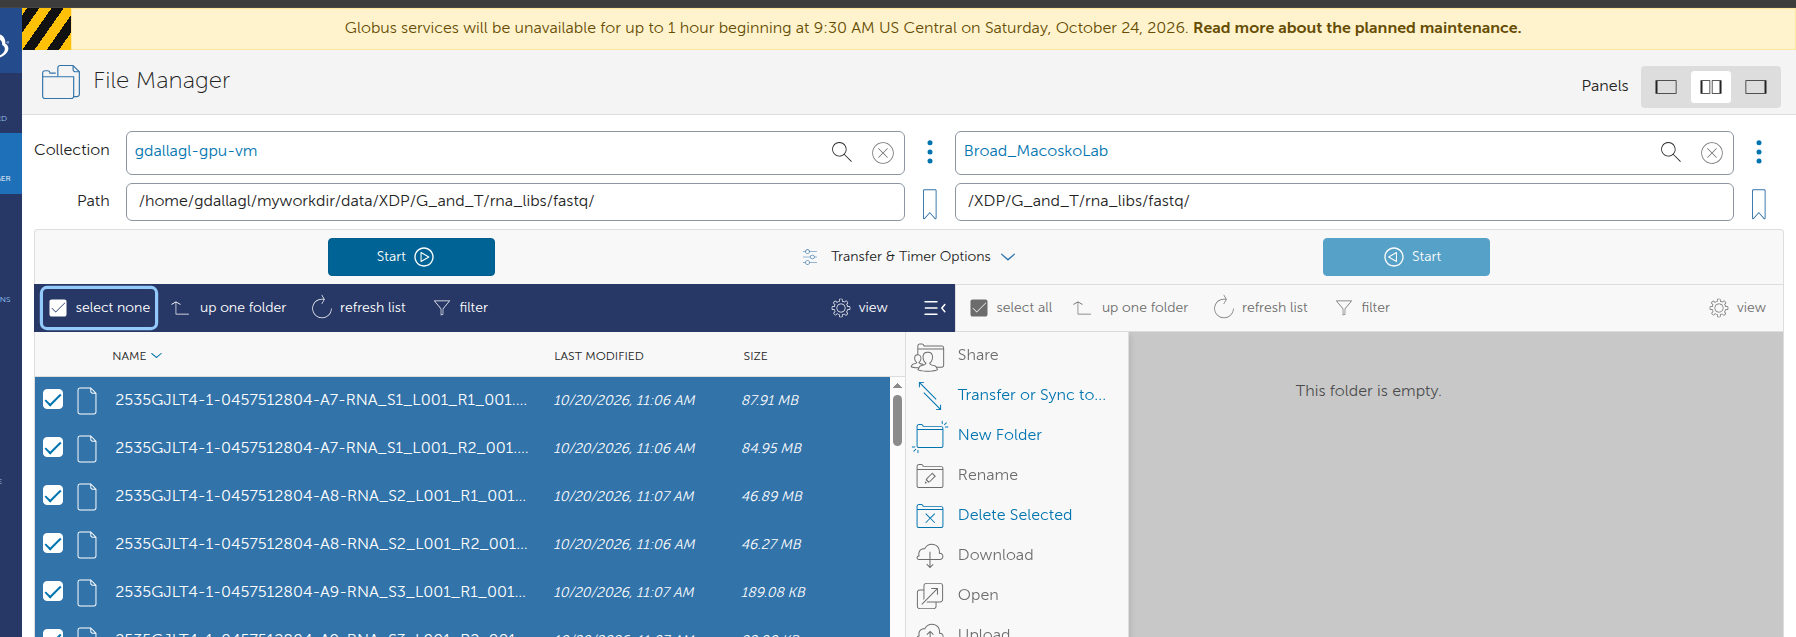

# Create Project in BaseJump

Wet lab tech used:
- ResolveOME
- BioSkryb Library Adapter Plate C #1000942, lot 0004
- NovaSeq X

link to teh project: https://basejumper.bioskryb.com/#/workspace/b9dbc50e-af67-4afa-b77a-3b0364c988e1/projects/OME


1. selct resolveOME 

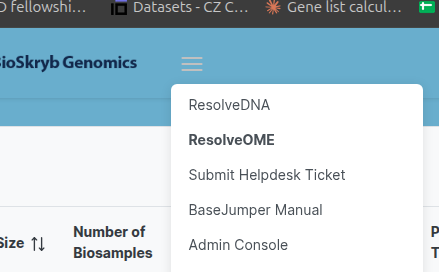

2. Create new project
    - fill correct lot ID
    - lib prepration
    - RNA proejct

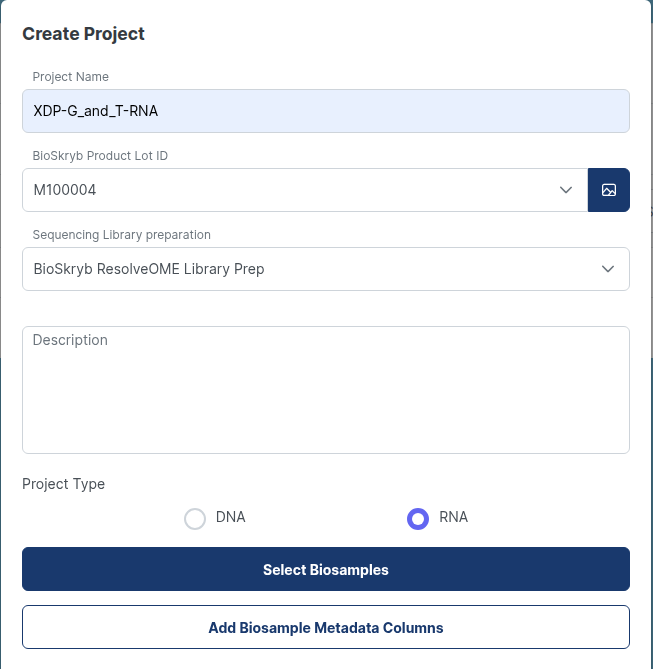

3. Add biosamples form "Shared data"

4. run pipelines
    - select BJ expression
    - Insturment: NovaSeq (LH00760)
        - to check on fastq: zcat yourfile_R1_001.fastq.gz | head -1
    - Genome: 38
    - readlength 150
        - to chek in fastq: zcat yourfile_R1_001.fastq.gz | head -4000 | awk 'NR%4==2{print length($0)}' | sort -n | uniq -c | tail -3
    - adapeter: leave waht they are
    - fastq subsmel: NO
    - 10X: N0
    - Cut adpeet: YES
    - CLuster QC plot: YES

# Copy DNA

In [8]:
%%bash

# ===== SETTINGS =====
DRY_RUN=true    # true = only show what would be downloaded, false = download

BUCKET_PATH="gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559aa7d36/fastqs/260826_SL-EXL_0486_A2535GJLT4/WALKUP-21131_0457512804_2026-08-28--14-56-01/fastq"
SAVE_PATH="/home/gdallagl/myworkdir/data/XDP/G_and_T/dna_libs/fastq/"
DISK_MOUNT="/home/gdallagl/myworkdir/data/XDP/G_and_T"   # used to check free space
PATTERN="$BUCKET_PATH/*_DNA_*.fastq.gz"

# ===== 1. List matching files with sizes =====
LISTING=$(gcloud storage ls -l "$PATTERN" 2>/dev/null | grep 'gs://')

if [ -z "$LISTING" ]; then
  echo "No files match: $PATTERN"
  exit 1
fi

N_FILES=$(echo "$LISTING" | wc -l)
TOTAL_BYTES=$(echo "$LISTING" | awk '{s += $1} END {printf "%.0f", s}')
FREE_BYTES=$(df -B1 --output=avail "$DISK_MOUNT" | tail -1)

echo "Files found:  $N_FILES"
echo "Total size:   $(awk -v b="$TOTAL_BYTES" 'BEGIN {printf "%.2f GB", b/1e9}')"
echo "Free on disk: $(awk -v b="$FREE_BYTES"  'BEGIN {printf "%.2f GB", b/1e9}')"
echo
echo "File names:"
echo "$LISTING" | awk '{printf "  %8.2f GB  %s\n", $1/1e9, $NF}' | sed 's|gs://.*/||'
echo

if [ "$TOTAL_BYTES" -gt "$FREE_BYTES" ]; then
  echo "WARNING: not enough free space on disk!"
fi

# ===== 2. Stop here if dry run =====
if [ "$DRY_RUN" = true ]; then
  echo "DRY RUN: nothing downloaded. Set DRY_RUN=false to download."
  exit 0
fi

# ===== 3. Download =====
mkdir -p "$SAVE_PATH"
gcloud storage cp "$PATTERN" "$SAVE_PATH"

# ===== 4. Verify =====
N_LOCAL=$(find "$SAVE_PATH" -maxdepth 1 -type f -name '*_DNA_*.fastq.gz' | wc -l)
echo
echo "Expected files:   $N_FILES"
echo "Downloaded files: $N_LOCAL"
du -sh "$SAVE_PATH"

Files found:  96
Total size:   382.93 GB
Free on disk: 212.37 GB

File names:
      6.05 GB  2535GJLT4_1_0457512804_A2_DNA_S4_L001_R1_001.fastq.gz
      6.20 GB  2535GJLT4_1_0457512804_A2_DNA_S4_L001_R2_001.fastq.gz
      7.83 GB  2535GJLT4_1_0457512804_A3_DNA_S5_L001_R1_001.fastq.gz
      8.07 GB  2535GJLT4_1_0457512804_A3_DNA_S5_L001_R2_001.fastq.gz
      3.87 GB  2535GJLT4_1_0457512804_A4_DNA_S6_L001_R1_001.fastq.gz
      3.96 GB  2535GJLT4_1_0457512804_A4_DNA_S6_L001_R2_001.fastq.gz
      0.04 GB  2535GJLT4_1_0457512804_B2_DNA_S13_L001_R1_001.fastq.gz
      0.04 GB  2535GJLT4_1_0457512804_B2_DNA_S13_L001_R2_001.fastq.gz
      8.48 GB  2535GJLT4_1_0457512804_B3_DNA_S14_L001_R1_001.fastq.gz
      8.68 GB  2535GJLT4_1_0457512804_B3_DNA_S14_L001_R2_001.fastq.gz
      0.00 GB  2535GJLT4_1_0457512804_B4_DNA_S15_L001_R1_001.fastq.gz
      0.00 GB  2535GJLT4_1_0457512804_B4_DNA_S15_L001_R2_001.fastq.gz
      3.41 GB  2535GJLT4_1_0457512804_C2_DNA_S22_L001_R1_001.fastq.gz
      3.50 GB  253

In [9]:
%%bash

cd /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/dna_libs/fastq || exit 1

declare -A sample_ids
i=1

for f in *_L001_R[12]_001.fastq.gz; do
    [ -f "$f" ] || continue

    sample="${f%_S*_L001_R[12]_001.fastq.gz}"
    clean="${sample//_/-}"

    if [[ -z "${sample_ids[$sample]+x}" ]]; then
        sample_ids[$sample]=$i
        ((i++))
    fi

    sid="${sample_ids[$sample]}"
    new="${clean}_S${sid}_L001_R${f#*_L001_R}"

    if [[ "$f" != "$new" ]]; then
        [[ ! -e "$new" ]] || { echo "ERROR: $new already exists"; exit 1; }
        mv -- "$f" "$new"
        echo "$f -> $new"
    fi
done

2535GJLT4_1_0457512804_D3_DNA_S32_L001_R1_001.fastq.gz -> 2535GJLT4-1-0457512804-D3-DNA_S49_L001_R1_001.fastq.gz
2535GJLT4_1_0457512804_D3_DNA_S32_L001_R2_001.fastq.gz -> 2535GJLT4-1-0457512804-D3-DNA_S49_L001_R2_001.fastq.gz


### Copy to BaseJump using Globus

### Run pipeline DNA-QC

Create new project with DNA lobs

# Run pipeline DNA-GWAS

### ATTENTION: only on good DNA libs foudn using 02 botbeook, QC metrics

# --------------------------

### Dowload bj-expression (RNA)

https://github.com/alextidd/bj-expression

In [ ]:
%%bash

# nectflow
cd ~
wget -qO- https://get.nextflow.io | bash
sudo mv nextflow /usr/local/bin/
nextflow -version

# docker
sudo apt-get update
sudo apt-get install -y ca-certificates curl
sudo install -m 0755 -d /etc/apt/keyrings
sudo curl -fsSL https://download.docker.com/linux/debian/gpg -o /etc/apt/keyrings/docker.asc
sudo chmod a+r /etc/apt/keyrings/docker.asc

echo "deb [arch=$(dpkg --print-architecture) signed-by=/etc/apt/keyrings/docker.asc] https://download.docker.com/linux/debian $(. /etc/os-release && echo "$VERSION_CODENAME") stable" | \
  sudo tee /etc/apt/sources.list.d/docker.list > /dev/null

sudo apt-get update
sudo apt-get install -y docker-ce docker-ce-cli containerd.io docker-buildx-plugin

sudo usermod -aG docker $USER

### Make a csv table for RNA libs

In [1]:
%%bash

DATA=/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs

echo "biosampleName,read1,read2,groups" > $DATA/input_rna.csv
for r1 in $DATA/fastq/*_RNA_*_R1_001.fastq.gz; do
  r2=${r1/_R1_001/_R2_001}
  name=$(basename "$r1" | sed -E 's/^2535GJLT4_1_0457512804_//; s/_S[0-9]+_L001_R1_001\.fastq\.gz$//')
  [ "$name" = "A9_RNA" ] && continue
  echo "$name,$r1,$r2,XDP" >> $DATA/input_rna.csv
done

wc -l $DATA/input_rna.csv      # expect 48 (header + 47 cells)
head -3 $DATA/input_rna.csv

48 /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/input_rna.csv
biosampleName,read1,read2,groups
A7_RNA,/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/fastq/2535GJLT4_1_0457512804_A7_RNA_S7_L001_R1_001.fastq.gz,/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/fastq/2535GJLT4_1_0457512804_A7_RNA_S7_L001_R2_001.fastq.gz,XDP
A8_RNA,/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/fastq/2535GJLT4_1_0457512804_A8_RNA_S8_L001_R1_001.fastq.gz,/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/fastq/2535GJLT4_1_0457512804_A8_RNA_S8_L001_R2_001.fastq.gz,XDP


### Download some refece

In [18]:
%%bash

REF=/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/references
mkdir -p $REF && cd $REF

E=https://ftp.ensembl.org/pub/release-104
wget -c $E/gtf/homo_sapiens/Homo_sapiens.GRCh38.104.chr.gtf.gz
wget -c $E/fasta/homo_sapiens/dna/Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz
wget -c $E/fasta/homo_sapiens/cdna/Homo_sapiens.GRCh38.cdna.all.fa.gz
wget -c $E/fasta/homo_sapiens/ncrna/Homo_sapiens.GRCh38.ncrna.fa.gz

wget -c -O hg38.HouseKeepingGenes.bed.gz \
  "https://sourceforge.net/projects/rseqc/files/BED/Human_Homo_sapiens/hg38.HouseKeepingGenes.bed.gz/download"

ls -lh

--2026-10-20 16:40:39--  https://ftp.ensembl.org/pub/release-104/gtf/homo_sapiens/Homo_sapiens.GRCh38.104.chr.gtf.gz
Resolving ftp.ensembl.org (ftp.ensembl.org)... 193.62.193.169
Connecting to ftp.ensembl.org (ftp.ensembl.org)|193.62.193.169|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 49691201 (47M) [application/x-gzip]
Saving to: ‘Homo_sapiens.GRCh38.104.chr.gtf.gz’

     0K .......... .......... .......... .......... ..........  0%  255K 3m10s
    50K .......... .......... .......... .......... ..........  0%  562K 2m18s
   100K .......... .......... .......... .......... ..........  0% 4.97M 95s
   150K .......... .......... .......... .......... ..........  0%  568K 93s
   200K .......... .......... .......... .......... ..........  0% 5.48M 76s
   250K .......... .......... .......... .......... ..........  0% 48.2M 63s
   300K .......... .......... .......... .......... ..........  0% 61.5M 54s
   350K .......... .......... .......... .......... ....

total 975M
-rw-r--r-- 1 gdallagl gdallagl  48M Mar 19  2021 Homo_sapiens.GRCh38.104.chr.gtf.gz
-rw-r--r-- 1 gdallagl gdallagl  71M Mar 27  2021 Homo_sapiens.GRCh38.cdna.all.fa.gz
-rw-r--r-- 1 gdallagl gdallagl 841M Mar 31  2021 Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz
-rw-r--r-- 1 gdallagl gdallagl  16M Mar 28  2021 Homo_sapiens.GRCh38.ncrna.fa.gz
-rw-r--r-- 1 gdallagl gdallagl 253K Jul 10  2015 hg38.HouseKeepingGenes.bed.gz


### Run tool

In [7]:
%%bash
sudo apt-get install -y acl
sudo setfacl -m u:gdallagl:rw /var/run/docker.sock
docker run --rm hello-world | head -3      # should work immediately, even in this session

Reading package lists...
Building dependency tree...
Reading state information...
The following packages were automatically installed and are no longer required:
  libpcre16-3 libpcre3 libpcre3-dev libpcre32-3 libpcrecpp0v5
Use 'sudo apt autoremove' to remove them.
The following NEW packages will be installed:
  acl
0 upgraded, 1 newly installed, 0 to remove and 30 not upgraded.
Need to get 61.2 kB of archives.
After this operation, 215 kB of additional disk space will be used.
Get:1 file:/etc/apt/mirrors/debian.list Mirrorlist [30 B]
Get:2 https://deb.debian.org/debian bookworm/main amd64 acl amd64 2.3.1-3 [61.2 kB]


dpkg-preconfigure: unable to re-open stdin: No such file or directory


Fetched 61.2 kB in 0s (512 kB/s)
Selecting previously unselected package acl.
(Reading database ... 144808 files and directories currently installed.)
Preparing to unpack .../archives/acl_2.3.1-3_amd64.deb ...
Unpacking acl (2.3.1-3) ...
Setting up acl (2.3.1-3) ...
Processing triggers for man-db (2.11.2-2) ...

Hello from Docker!
This message shows that your installation appears to be working correctly.


In [8]:
%%bash
getent group docker                 # expect: docker:x:992:gdallagl

id -nG                              # expect "docker" in the list

systemctl is-active docker          # expect: active

ls -l /var/run/docker.sock          # expect: srw-rw---- 1 root docker ...

docker run --rm hello-world | head -3    # expect: "Hello from Docker!"



docker:x:992:gdallagl
gdallagl adm dip video plugdev ollama google-sudoers
active
srw-rw----+ 1 root docker 0 Oct 20 15:14 /var/run/docker.sock

Hello from Docker!
This message shows that your installation appears to be working correctly.


In [12]:
%%bash
sudo mkdir -p /etc/systemd/system/docker.service.d
printf '[Service]\nExecStartPost=/usr/bin/setfacl -m u:gdallagl:rw /var/run/docker.sock\n' | \
  sudo tee /etc/systemd/system/docker.service.d/socket-acl.conf
sudo systemctl daemon-reload
sudo systemctl restart docker
sleep 3
ls -l /var/run/docker.sock                 # should still end with "+"
docker run --rm hello-world | head -2

[Service]
ExecStartPost=/usr/bin/setfacl -m u:gdallagl:rw /var/run/docker.sock
srw-rw----+ 1 root docker 0 Oct 20 15:14 /var/run/docker.sock

Hello from Docker!


In [ ]:
%%bash

export NXF_VER=24.04.4
DATA=/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T
CODE=$DATA/bj-expression
RUN=$DATA/rna_libs/runs/qc

# Check the two input files exist before launching
ls -l $DATA/local.config $DATA/rna_libs/input_rna.csv || exit 1

mkdir -p $RUN && cd $RUN

ARGS=(
  -c $DATA/local.config            # Docker, S3 access, resource caps
  -w $DATA/work                    # Nextflow scratch space (big, deletable afterwards)
  --input_csv $DATA/rna_libs/input_rna.csv  # sample list
  --publish_dir $RUN/results       # where final results are copied
  --max_cpus 30                    # max CPUs per step
  --max_memory 200.GB              # max RAM per step
  --genome GRCh38                  # human reference
  --skip_subsampling false         # QC run: subsample to 100k reads per cell
  --resume
)

nextflow run $CODE/main.nf "${ARGS[@]}" -bg > run.log
echo "Launched. Follow with: tail -f $RUN/run.log"

-rw-r--r-- 1 gdallagl gdallagl   213 Oct 20 16:17 /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/local.config
-rw-r--r-- 1 gdallagl gdallagl 11480 Oct 20 16:03 /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/input_rna.csv


Nextflow 26.10.2 is available - Please consider updating your version to it


Launched. Follow with: tail -f /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/runs/qc/run.log


In [16]:
%%bash
B=s3://bioskryb-public-data/pipeline_resources

# 1. Top level: public?
aws s3 ls $B/ --no-sign-request | head

# 2. The two folders that failed: can we list them?
aws s3 ls $B/genomes/Homo_sapiens/NCBI/GRCh38/Sequence/salmon_chr_eqnames_wgs/index/ --no-sign-request | head
aws s3 ls $B/genomes/Homo_sapiens/NCBI/GRCh38/Sequence/star_chr_eqnames_wgs/index_ensemble/ --no-sign-request | head

# 3. Is anonymous access set in your config, and are there AWS keys on the VM that could interfere?
grep -A2 "aws" /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/local.config
ls ~/.aws 2>/dev/null && echo "AWS config found"

# 4. Which reference files does the pipeline want for GRCh38?
sed -n "/GRCh38/,/}/p" /home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/bj-expression/nf-bioskryb-utils/conf/genomes.config | head -30


An error occurred (AccessDenied) when calling the ListObjectsV2 operation: Access Denied

An error occurred (AccessDenied) when calling the ListObjectsV2 operation: Access Denied

An error occurred (AccessDenied) when calling the ListObjectsV2 operation: Access Denied


aws {
  client { anonymous = true }
}
        'GRCh38' {
            
            reference                     = "${params.genomes_base}/genomes/Homo_sapiens/NCBI/GRCh38/Annotation/GATK_bundle/Sequence"
            base_metrics_intervals        = "${params.genomes_base}/genomes/Homo_sapiens/NCBI/GRCh38/Annotation/Intervals/wgs_intervals.bed"
            dbsnp                         = "${params.genomes_base}/genomes/Homo_sapiens/NCBI/GRCh38/Annotation/GATK_bundle/dbsnp_138/dbsnp.vcf.gz"
            dbsnp_index                   = "${params.genomes_base}/genomes/Homo_sapiens/NCBI/GRCh38/Annotation/GATK_bundle/dbsnp_138/dbsnp.vcf.gz.tbi"
            clinvar                       = "${params.genomes_base}/genomes/Homo_sapiens/NCBI/GRCh38/Annotation/Clinvar/20220214/clinvar.vcf.gz"
            clinvar_index                 = "${params.genomes_base}/genomes/Homo_sapiens/NCBI/GRCh38/Annotation/Clinvar/20220214/clinvar.vcf.gz.tbi"
            mills                         = "${params.genomes